<a href="https://colab.research.google.com/github/ReDanBorn/MathStat/blob/main/4_%D0%94%D0%BE%D0%B2%D0%B5%D1%80%D0%B8%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D1%8B%D0%B5_%D0%B8%D0%BD%D1%82%D0%B5%D1%80%D0%B2%D0%B0%D0%BB%D1%8B_%D1%81%D1%82%D0%B0%D1%82%D0%B8%D1%81%D1%82%D0%B8%D0%BA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Доверительные интервалы статистик и их оценки

**Набор данных**

В исследовании приняли участие 634 человека, каждому из которых был предоставлен трекер Fitbit для мониторинга сна и физической активности. Данные об успеваемости студентов (GPA) были получены из регистратуры университета. Каждая строка в наборе данных представляет информацию об одном участнике.

Исследователи проанализировали данные с Fitbit и выделили эпизоды сна — периоды, когда устройство определяло, что участник спит. Учитывались только эпизоды продолжительностью не менее 20 минут, при этом они должны были быть разделены между собой промежутком минимум 5 минут. Промежутки меньше 5 минут игнорировались — например, если студент спал несколько часов, ненадолго проснулся и снова заснул, это считалось одним эпизодом.

Основной эпизод сна определялся как самый продолжительный период сна между полуднем одного дня и полуднем следующего. Всё остальное относилось к дневному сну. Например, если студент спал с 16:00 до 17:00, а затем с 2:00 до 8:00 следующего дня, период с 2:00 до 8:00 считался основным эпизодом (6 часов), а период с 16:00 до 17:00 — часом дневного сна. Начало основного эпизода определялось как время отхода ко сну — в приведённом примере это было 2:00 ночи.


**Факторы в наборе данных**
- **subject_id** - уникальный идентификатор, присваиваемый каждому участнику исследования для его однозначной идентификации в базе данных
- **study** - порядковый номер исследовательского проекта, который можно найти в представленной таблице
- **cohort** - специальное кодовое обозначение группы участников, к которой относится конкретный испытуемый
- **demo_race** - бинарный показатель принадлежности к недостаточно представленным этническим группам (значение 0 означает принадлежность, 1 - отсутствие принадлежности). Исследователи относят к недостаточно представленным группам лиц, имеющих хотя бы одного родителя чернокожего, латиноамериканского, коренного американского или тихоокеанского происхождения. К не недостаточно представленным группам причисляются лица, оба родителя которых принадлежат к белой или азиатской расе
- **demo_gender** - половая принадлежность участника (0 соответствует мужскому полу, 1 - женскому), зафиксированная учебным заведением
- **demo_firstgen** - индикатор статуса первого поколения в семье (0 - не первое поколение, 1 - первое поколение). Участником первого поколения считается студент, чьи родители не имеют высшего образования (имеют только аттестат о среднем образовании)
- **bedtime_mssd** - метрика, отражающая вариабельность времени отхода ко сну, вычисляемая как среднее значение квадратов разностей между последовательными значениями времени отхода ко сну (в часах). В отличие от стандартного отклонения, данный показатель оценивает изменения от дня к дню, а не относительно среднего значения за весь период
- **TotalSleepTime** - усреднённое время фактического сна, рассчитываемое как разница между временем в постели и периодами бодрствования в основной эпизод сна (в минутах)
- **midpoint_sleep** - усреднённое время середины периода сна, измеряемое в минутах, прошедших после 23:00 (например, значение 364 соответствует 05:04 следующего дня)
- **frac_nights_with_data** - процент ночей, за которые удалось собрать данные о сне участника (учитываются случаи, когда участники не носили трекер или устройство разряжалось)
- **daytime_sleep** - усреднённая продолжительность дневного сна и дремоты вне основного периода ночного сна (в минутах)
- **cum_gpa** - совокупный средний балл успеваемости студента за все предыдущие семестры (для первокурсников обычно отражает результаты только осеннего семестра)
- **term_gpa** - итоговый средний балл успеваемости за текущий семестр по 4-балльной шкале
- **term_units** - количество академических единиц (кредитов), которые студент осваивает в текущем семестре
- **Zterm_units_ZofZ** - стандартизированный показатель академической нагрузки, учитывающий различия в системах подсчёта единиц между учебными заведениями. Сначала нагрузка каждого студента нормируется относительно среднего значения по его группе, затем все полученные значения повторно стандартизируются. Нулевое значение соответствует средней нагрузке, положительные числа указывают на повышенную, отрицательные - на пониженную нагрузку по сравнению со средним показателем


In [60]:
# from google.colab import drive
# drive.mount('/content/drive')

## Импорт библиотек, данных и предпросмотр

In [61]:
import numpy as np
import pandas as pd
import statsmodels as sm
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# Игнорирование предупреждений связанных с версиями
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Параметры распределения
mpl.rcParams.update({'font.size': 18, 'figure.figsize': (9, 9)})

df_sleep = pd.read_csv('./cmu-sleep.csv')


In [62]:
df_sleep.info()

<class 'pandas.DataFrame'>
RangeIndex: 634 entries, 0 to 633
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   subject_id             634 non-null    int64  
 1   study                  634 non-null    int64  
 2   cohort                 634 non-null    str    
 3   demo_race              634 non-null    str    
 4   demo_gender            634 non-null    str    
 5   demo_firstgen          634 non-null    str    
 6   bedtime_mssd           634 non-null    float64
 7   TotalSleepTime         634 non-null    float64
 8   midpoint_sleep         634 non-null    float64
 9   frac_nights_with_data  634 non-null    float64
 10  daytime_sleep          634 non-null    float64
 11  cum_gpa                634 non-null    float64
 12  term_gpa               634 non-null    float64
 13  term_units             634 non-null    str    
 14  Zterm_units_ZofZ       634 non-null    str    
dtypes: float64(7), in

In [63]:
# Дропнем служебный столбец
df_sleep = df_sleep.drop('subject_id', axis=1)

# Выведем описательные статистики
df_sleep.describe()

,study,bedtime_mssd,TotalSleepTime,midpoint_sleep,frac_nights_with_data,daytime_sleep,cum_gpa,term_gpa
count,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000
mean,3.181388,0.451688,397.323874,398.679186,0.867439,41.164241,3.465596,3.449598
std,1.317125,1.393632,50.856725,72.710945,0.178960,27.389418,0.437577,0.500467
min,1.000000,0.004505,194.782609,247.071429,0.214286,2.269231,1.210000,0.350000
25%,2.000000,0.074694,366.930077,345.182692,0.821429,23.097826,3.232283,3.233333
50%,3.000000,0.135007,400.395833,388.245726,0.932184,34.982143,3.557833,3.555667
75%,4.000000,0.291698,430.114583,437.655263,1.000000,51.248538,3.789545,3.810000
max,5.000000,20.849225,587.666667,724.666667,1.000000,292.304348,4.000000,4.000000


Во-первых, выборка включает 634 наблюдения, что является достаточно большим объёмом для статистического анализа. Переменные представлены как категориальные (например, study), так и числовые (например, TotalSleepTime, cum_gpa, term_gpa).

- Переменная study
Это дискретная категориальная переменная с диапазоном значений от 1 до 5 и средним около 3.18. Судя по стандартному отклонению (1.32), наблюдения распределены достаточно равномерно по уровням, без сильного смещения к какому-то одному значению.

- Показатель bedtime_mssd
Среднее значение около 0.45 при стандартном отклонении 1.39 и минимуме, близком к нулю, говорит о том, что большинство наблюдений сосредоточено около очень малых значений, но существуют большие выбросы (максимум более 20). Это свидетельствует о сильно скошенном вправо распределении, характерном для метрик вариабельности сна.

- Общее время сна (TotalSleepTime)
Среднее составляет примерно 397 минут (около 6,6 часов), при этом стандартное отклонение — 51 минута. Минимальное значение около 195 минут (3,25 часа), а максимальное — почти 588 минут (почти 10 часов). Основная масса наблюдений находится в диапазоне 367–430 минут (6–7,2 часов). Это относительно сжатое распределение, без экстремальных выбросов.

- Середина сна (midpoint_sleep)
Среднее значение около 399 минут (≈6 часов 40 минут после полуночи), при стандартном отклонении 72 минут. Минимум и максимум показывают существенный разброс — от 247 до 725 минут (≈4:07 утра до ≈12:05 дня). Это указывает на разнообразные привычки сна в выборке — от «жаворонков» до «сов».

- Доля ночей с данными (frac_nights_with_data)
Медиана и верхний квартиль равны 0.93 и 1 соответственно, что говорит о высокой полноте данных для большинства участников. Минимум около 0.21 может отражать отдельные неполные записи.

- Дневной сон (daytime_sleep)
Среднее 41 минута с очень большим стандартным отклонением (27 мин) и экстремальным максимумом 292 минут (почти 5 часов). Это распределение явно скошено вправо, и можно ожидать наличие аномалий/выбросов.

- Успеваемость (cum_gpa и term_gpa)
Средний кумулятивный GPA составляет 3.46, а средний GPA за семестр — 3.45, что очень близко. Стандартное отклонение около 0.44–0.50 говорит о сравнительно небольшой вариативности. Минимальные значения около 1.2–0.35 указывают на редкие случаи с очень низкой успеваемостью, но максимальные значения во всех случаях равны 4.0, что отражает систему оценивания.

**Общие выводы:**

- Большинство переменных распределено достаточно равномерно без сильных пропусков, но ряд признаков (особенно bedtime_mssd и daytime_sleep) содержат длинные хвосты и выбросы, что потребует внимания на этапе анализа.

- Показатели сна варьируются в пределах физиологически допустимых значений, однако встречаются экстремальные случаи, которые могут повлиять на модельные выводы.

- Успеваемость у большинства студентов довольно высокая и стабильная, с небольшим разбросом.

- Данные в целом выглядят пригодными для дальнейшего анализа и построения моделей, но потребуется работа с выбросами и проверка распределений для корректного применения статистических методов.

In [64]:
# Выделим числовые факторы
num_cols = list(df_sleep.dtypes[df_sleep.dtypes != 'object'].index)
print(num_cols)

['study', 'cohort', 'demo_race', 'demo_gender', 'demo_firstgen', 'bedtime_mssd', 'TotalSleepTime', 'midpoint_sleep', 'frac_nights_with_data', 'daytime_sleep', 'cum_gpa', 'term_gpa', 'term_units', 'Zterm_units_ZofZ']


### Визуализация числовых факторов

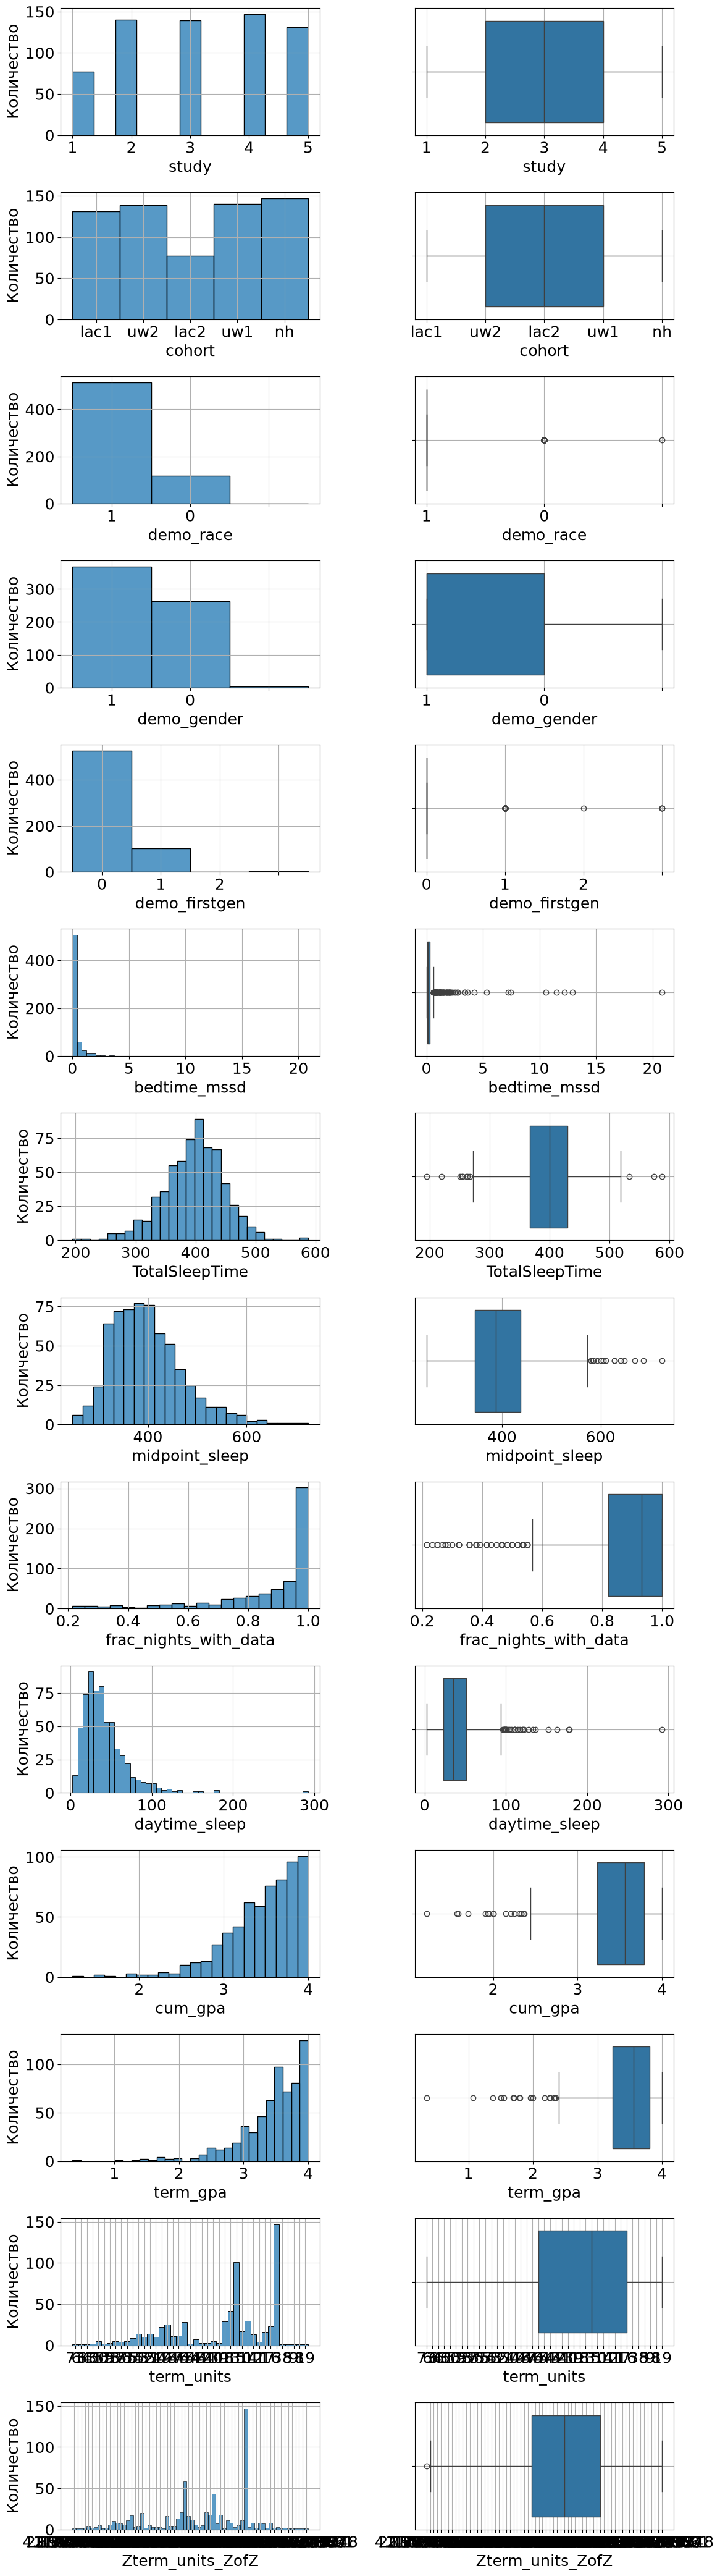

In [65]:
fig, ax = plt.subplots(len(num_cols), 2, figsize=(12, 3*len(num_cols)))
for idx,col in enumerate(num_cols):
    sns.histplot(data=df_sleep, x=col, ax=ax[idx, 0])
    ax[idx, 0].set_ylabel('Количество')
    ax[idx, 0].grid()
    sns.boxplot(data=df_sleep, x=col, ax=ax[idx, 1])
    ax[idx, 1].grid()
plt.tight_layout()
plt.show()

Вывод по каждой визуализации
- **`study`**
 дискретная категориальная переменная с равномерным распределением по уровням (1–5). Каждая группа содержит примерно одинаковое количество наблюдений. Распределение предполагается как многомодальное, категориальное, ближе к равномерному на конечном множестве.

- **`bedtime_mssd`** большинство наблюдений сосредоточено вблизи нуля, есть длинный хвост вправо. На boxplot видны значительные выбросы. Распределение характерно для экспоненциального распределения или распределения с тяжёлым правым хвостом (например, логнормальное).

- **`TotalSleepTime`** распределение близко к симметричному с центром около 400 минут. Наблюдаются слабые хвосты, но без экстремальных выбросов. Распределение визуально похоже на нормальное распределение.

- **`midpoint_sleep`** колоколоподобное распределение с центром около 400 минут. Лёгкие хвосты в обе стороны, небольшие выбросы. Распределение близко к нормальному или логнормальному распределению.

- **`frac_nights_with_data`** распределение сосредоточено у верхней границы (около 1). Большинство студентов почти полностью имеют данные по ночам. Распределение характерно для бета-распределения, смещённого в сторону правой границы.

- **`daytime_sleep`** сильная концентрация вблизи нуля, длинный правый хвост, редкие большие значения (до 300 минут). На boxplot много выбросов. Распределение похоже на экспоненциальное или гамма-распределение.

- **`cum_gpa`** значения сосредоточены ближе к верхней границе (3–4). Наблюдается правый сдвиг, чем выше GPA, тем больше студентов. Распределение напоминает бета-распределение, смещённое в сторону 1 (верхней границы). Нормальности нет.

- **`term_gpa`** аналогично cum_gpa — значения скапливаются около верхней границы (3–4). Есть отдельные низкие выбросы (ниже 2). Распределение также напоминает бета-распределение с концентрацией у правого края.



**Общие выводы:**

- Нормальное распределение вероятно для `TotalSleepTime`, `midpoint_sleep`.
- Сильная асимметрия (правый хвост) для `bedtime_mssd`, `daytime_sleep`.
- Смещение к границе распределения (правый край) для `frac_nights_with_data`, `cum_gpa`, `term_gpa`.
- Категориальное распределение: `study`.

## Квантиль-квантильные графики

### Идея метода

QQ-график основан на сравнении **эмпирических квантилей выборки** с **теоретическими квантилями** предполагаемого распределения.

- Если данные действительно подчиняются выбранному распределению, то точки графика должны располагаться примерно на прямой линии $y = x$ (с поправкой на масштаб и сдвиг).
- Если распределение отличается, отклонения от прямой линии будут указывать на характер этого отличия.

### Построение QQ-графика

Пусть есть выборка $x_1, x_2, \dots, x_n$​.

1. **Упорядочивание данных**  
    Расположим элементы выборки в порядке возрастания:
    
    $$x_{(1)} \leq x_{(2)} \leq \dots \leq x_{(n)}.$$
    
2. **Определение эмпирических квантилей**  
    Для каждого упорядоченного наблюдения $x_{(i)}$​ сопоставим вероятность:
    
    $$p_i = \frac{i - 0.5}{n}, \quad i = 1, 2, \dots, n.$$
    
    Эти значения $p_i$​ можно рассматривать как эмпирические квантили.
    
3. **Вычисление теоретических квантилей**  
    Для предполагаемого распределения с функцией квантиля $F^{-1}(p)$ найдём значения:
    
    $$q_i = F^{-1}(p_i), \quad i = 1, 2, \dots, n.$$
4. **Построение графика**  
    Строим точки $(q_i, x_{(i)})$.
    
    - По оси $x$ — теоретические квантили.
        
    - По оси $y$ — эмпирические квантили (упорядоченные данные выборки).


### Интерпретация формы QQ-графика

- **Прямая линия (почти совпадает с диагональю)**  
    Данные хорошо согласуются с предполагаемым распределением.
    
- **S-образная кривая (выпуклость)**
    
    - Если точки выше диагонали в хвостах и ниже в середине — у данных более тяжёлые хвосты, чем у предполагаемого распределения.
        
    - Если наоборот — хвосты легче (например, выборка ближе к распределению с более «сжатыми» хвостами).
        
- **Изломы или асимметрия**  
    Указывают на смещённость распределения (асимметрия вправо или влево).
    
- **Расхождение в начале или в конце**  
    Свидетельствует о проблемах в крайних значениях (например, наличие выбросов).

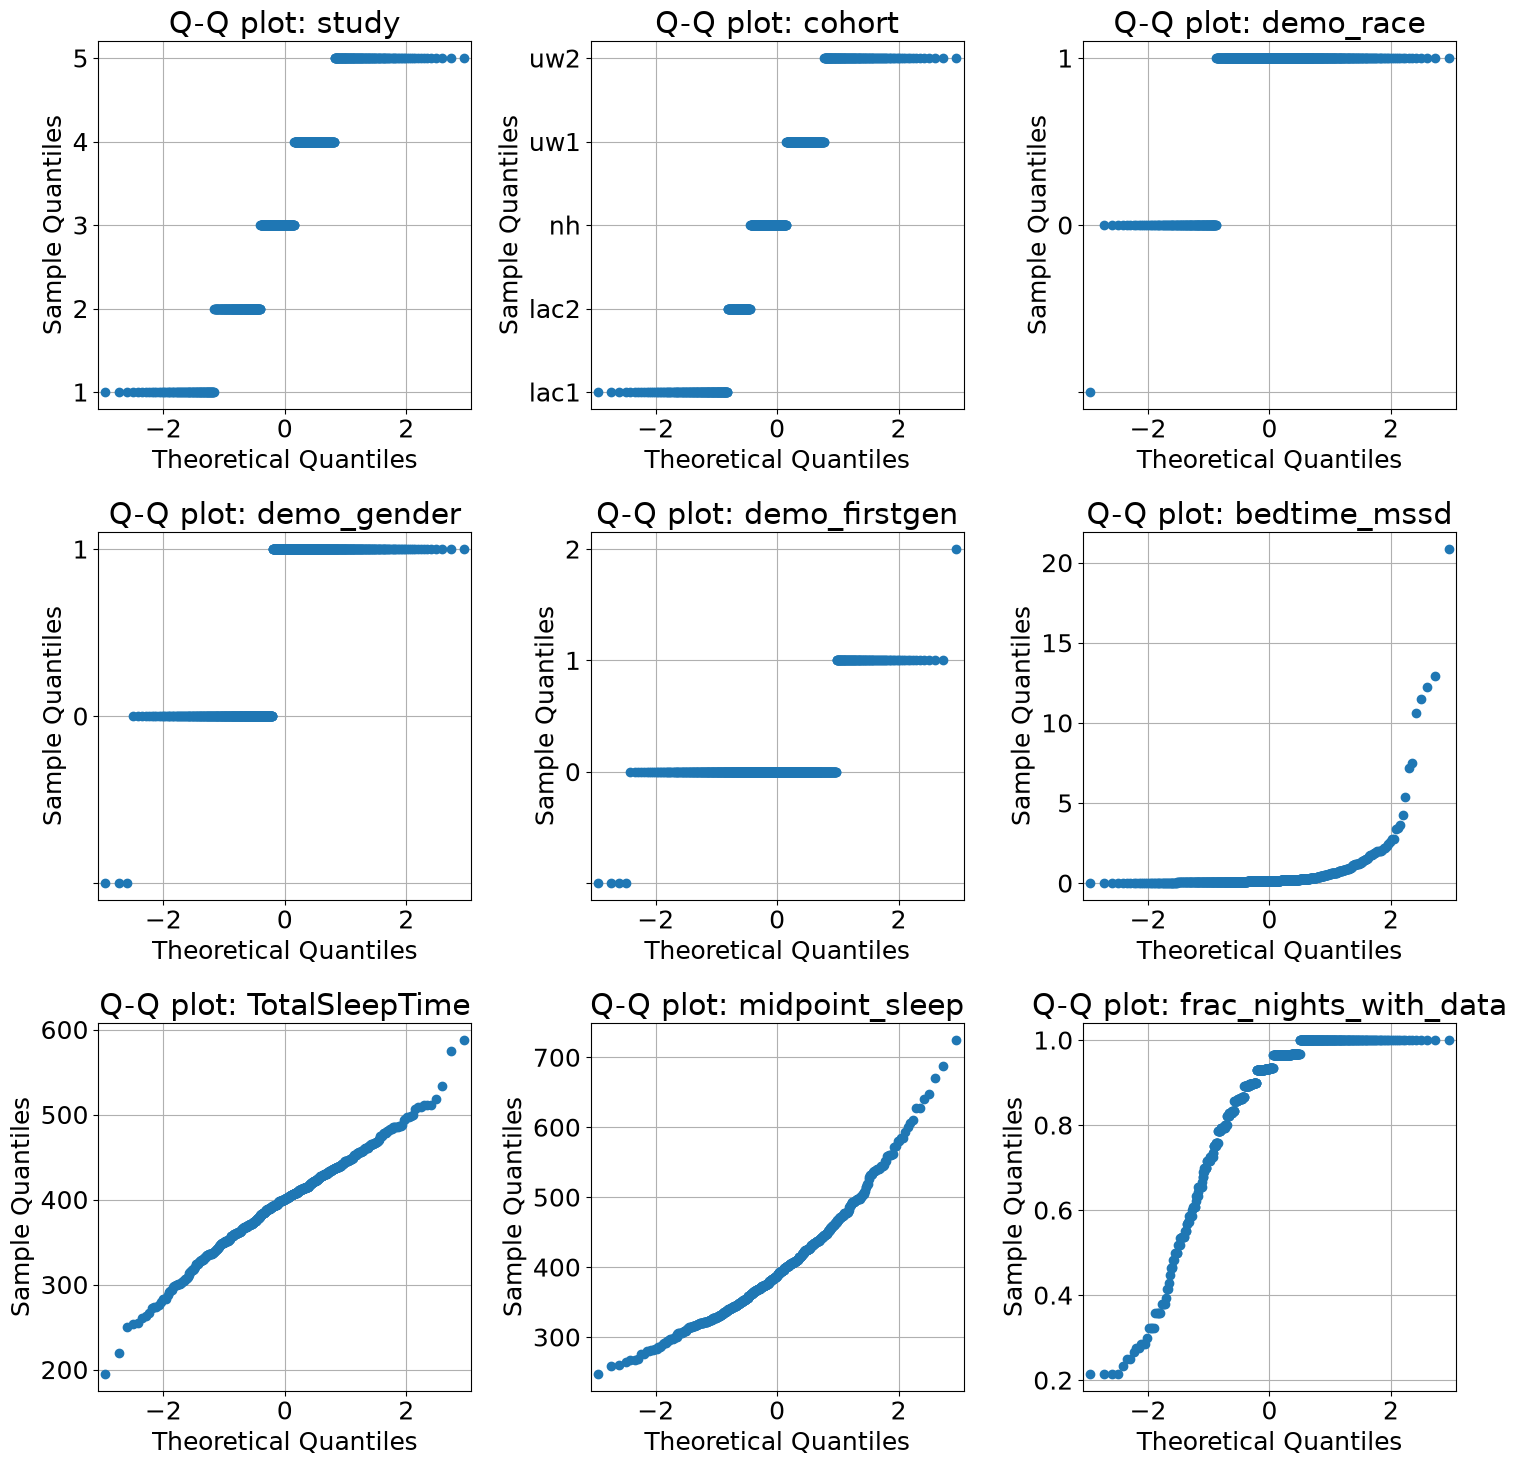

In [66]:
from statsmodels.graphics.gofplots import qqplot

# Построение Q-Q графиков
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

# Для каждой колонки строим QQ-график
for ax, col in zip(axes.flatten(), num_cols):
    qqplot(df_sleep[col].dropna(), ax=ax)
    ax.set_title(f"Q-Q plot: {col}")
    ax.grid()

# Убираем пустые оси (если есть)
for j in range(len(num_cols), len(axes.flatten())):
    fig.delaxes(axes.flatten()[j])

plt.tight_layout()
plt.show()

**Интерпретация**

- **`TotalSleepTime`** — точки наиболее близки к диагонали; распределение близко к нормальному (с некоторыми хвостами).

- **`midpoint_sleep`** — тоже похоже на нормальное, но заметна асимметрия в хвостах.

- **`bedtime_mssd`**, **`daytime_sleep`** — сильные отклонения от линии, ярко выраженные тяжёлые хвосты; нормальность отвергается.

- **`frac_nights_with_data`** — данные сжаты у верхней границы (1), распределение не похоже на нормальное, скорее бета-тип.

- **`cum_gpa`**, **`term_gpa`** — отклоняются от нормальности, особенно в верхней части, где значения ограничены максимумом 4.0. Это указывает на смещённость и ограниченность диапазона.

### Преобразование Бокса-Кокса

Многие статистические методы (например, линейная регрессия, ANOVA, t-тесты) предполагают нормальность распределения ошибок и примерно одинаковую дисперсию (гомоскедастичность).
На практике часто данные имеют:
- сильную асимметрию (правый или левый хвост),
- непостоянную дисперсию,
- прижатость к границам (например, все значения положительные).

Преобразование Бокса–Кокса применяется, чтобы «нормализовать» данные и стабилизировать дисперсию.

Таким образом, методы повторных подвыборок позволяют отказаться от строгих предположений о распределении данных и использовать только эмпирическую информацию. Это особенно важно для реальных данных, где нормальность и другие классические предпосылки часто не выполняются.

#### Формула преобразования

Для случайной величины $y > 0$ (обязательно положительные значения!) преобразование определяется как:

$$y^{(\lambda)} = \begin{cases} \dfrac{y^\lambda - 1}{\lambda}, & \lambda \neq 0, \\[1em] \ln(y), & \lambda = 0. \end{cases}$$

- $\lambda$ — параметр преобразования (степень), подбирается так, чтобы результат был **максимально близок к нормальному распределению**.
    
- При $\lambda = 1$ преобразование совпадает с исходными данными (нет изменений).
    
- При $\lambda = 0$ мы фактически получаем логарифмирование.

#### Интуиция

- **Если распределение сильно скошено вправо (тяжёлый правый хвост)**, то подходят значения $\lambda < 1$ (логарифмирование, квадратный корень, обратное преобразование).
    
- **Если распределение скошено влево,** то подходят значения $\lambda > 1$ (например, квадрат).

#### Как выбирается $\lambda$

Задача: найти такое $\lambda$, при котором данные становятся максимально похожи на нормальное распределение.  
Обычно используется метод максимального правдоподобия (MLE):
- оценивается логарифм функции правдоподобия при разных $\lambda$,
- выбирается $\lambda$, при котором достигается максимум.

#### Ограничения

- Работает только для **положительных данных**. Если есть нули или отрицательные значения, нужно сначала сдвинуть распределение (например, $y + c$, где $c > 0$).
    
- Не всегда удаётся получить идеально нормальное распределение (например, если данные прижаты к границам, как в случае с `frac_nights_with_data`).
    
- Иногда лучше использовать **обобщение — преобразование Йео–Джонсона**, которое допускает и отрицательные значения.

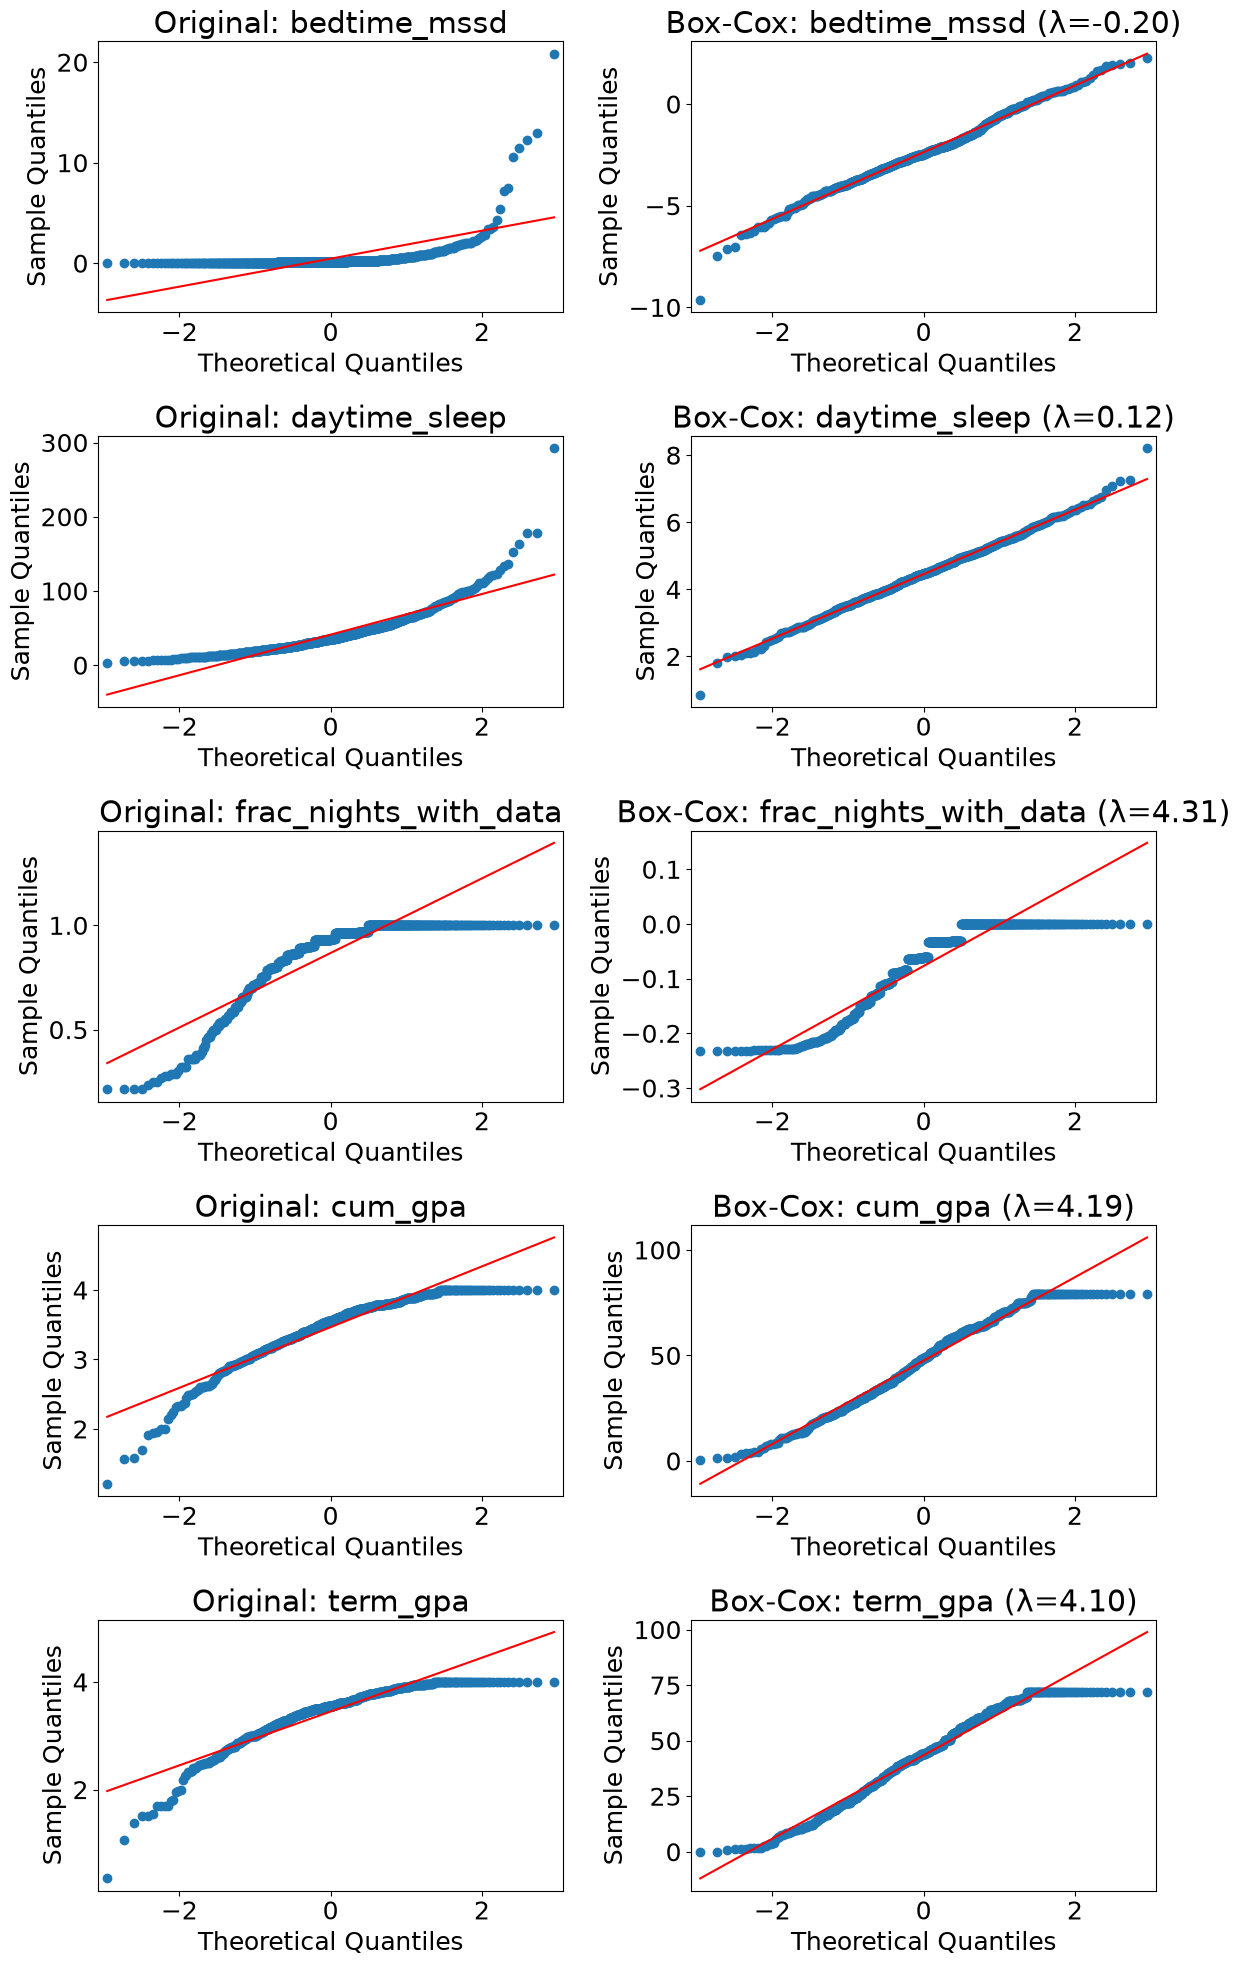

In [67]:
from scipy.stats import boxcox
import numpy as np

# Функция для применения логарифма и Box-Cox, если данные положительные
def transform_data(series):
    data = series.dropna()
    transformations = {}

    # Box-Cox (только для положительных значений)
    if (data > 0).all():
        transformed, lmbda = boxcox(data)
        transformations["boxcox"] = transformed
        transformations["boxcox_lambda"] = lmbda

    return transformations

# Применим трансформации к проблемным признакам
problematic_cols = ["bedtime_mssd", "daytime_sleep", "frac_nights_with_data", "cum_gpa", "term_gpa"]
transformed_results = {}

for col in problematic_cols:
    transformed_results[col] = transform_data(df_sleep[col])

# Строим Q-Q графики для трансформированных данных
fig, axes = plt.subplots(len(problematic_cols), 2, figsize=(12, 20))

for i, col in enumerate(problematic_cols):
    data = df_sleep[col].dropna()
    qqplot(data, line='s', ax=axes[i,0])
    axes[i,0].set_title(f"Original: {col}")

    if "boxcox" in transformed_results[col]:
        qqplot(transformed_results[col]["boxcox"], line='s', ax=axes[i,1])
        axes[i,1].set_title(f"Box-Cox: {col} (λ={transformed_results[col]['boxcox_lambda']:.2f})")
    else:
        axes[i,1].axis('off')

plt.tight_layout()
plt.show()

**Выводы по графикам:**

- **`bedtime_mssd`**
После Box–Cox (λ ≈ -0.20) распределение стало значительно ближе к нормальному.

- **`daytime_sleep`**
Box–Cox (λ ≈ 0.12) устранил сильный правый хвост, точки хорошо легли на диагональ.

- **`frac_nights_with_data`**
Box–Cox (λ ≈ 4.31) частично улучшил симметрию, но из-за того, что данные прижаты к верхней границе, нормальности добиться сложно.

- **`cum_gpa`** и **`term_gpa`**
Box–Cox (λ ≈ 4.1) сгладил распределение, убрав сжатие к верхней границе, визуально стало ближе к нормальному.

Наиболее эффективно Box–Cox улучшает распределения `bedtime_mssd` и `daytime_sleep`.

Для `cum_gpa` и `term_gpa` трансформация помогает, но ограничения диапазона (максимум 4.0) всё равно видны.

`frac_nights_with_data` остаётся проблемным, так как большинство значений прижаты к 1 — возможно, его лучше использовать как категориальный/бинарный признак.

Возможно в будущем имеет смысл преобразовать данные факторов и меток к более нормальному виду, делать предсказательные модели на таких данных и возвращать обратно значения к исходным шкалам.

# Различие между выборочными оценками и параметрами распределения

  

В статистике важно различать **истинные параметры распределения** и их **выборочные оценки по данным**.  

## Среднее и математическое ожидание

-   **Математическое ожидание** $\mu = \mathbb{E}[X]$ --- теоретическая характеристика случайной величины, определяемая формулой

    $$ \mu = \int_{-\infty}^{+\infty}x f(x),dx, $$ где $f(x$) --- плотность вероятности.

 Это фиксированное число, которое не зависит от конкретной выборки.

-   **Выборочное среднее**

    $$ \bar{X} = \frac{1}{n}\sum_{i=1}^n X_i$$

    --- эмпирическая оценка математического ожидания на основе конечных данных. Оно случайно и изменяется от выборки к выборке.

## Стандартное отклонение и среднеквадратическое отклонение

  

-   **Стандартное отклонение**

    $$\sigma = \sqrt{\mathbb{E}[(X-\mu)^2]}$$

    --- теоретическая характеристика распределения, мера разброса относительно математического ожидания.

  

-   **Выборочное среднеквадратическое отклонение**

    $$S = \sqrt{\frac{1}{n-1}\sum_{i=1}^n (X_i-\bar{X})^2}$$

    --- оценка стандартного отклонения по данным. $S$ хорошо аппроксимирует $\sigma$ для симметричных распределений.

  

## Как можно оценить параметры на основе гистограммы?

  

Гистограмма даёт приближение плотности распределения. Используя её, можно вычислить интегральные характеристики, не обращаясь напрямую к исходным наблюдениям.

Пусть гистограмма имеет высоты $h_j$, середины интервалов $c_j$ и ширину $\Delta$. Тогда приближения будут такими:

-   математическое ожидание

    $$\hat{\mu}_{hist} = \sum_j c_j\cdot h_j \cdot \Delta$$

-   дисперсия
    $$\hat{\sigma}^2_{hist} = \sum_j (c_j - \hat{\mu}_{hist})^2 \cdot h_j \cdot \Delta$$

-   стандартное отклонение
    $$\hat{\sigma}_{hist} =\sqrt{\hat{\sigma}^2_{hist}}. $$


Таким образом, **выборочные оценки** (среднее и стандартное отклонение) используют исходные данные напрямую, а **гистограммные оценки** приближают интегральные характеристики распределения через эмпирическую плотность.

Оценка мат. ожидания по гистограмме: 4.8804
Оценка среднего по данным: 4.8753
Оценка стандартного отклонения по гистограмме: 1.9990
Оценка СКО по данным: 1.9991


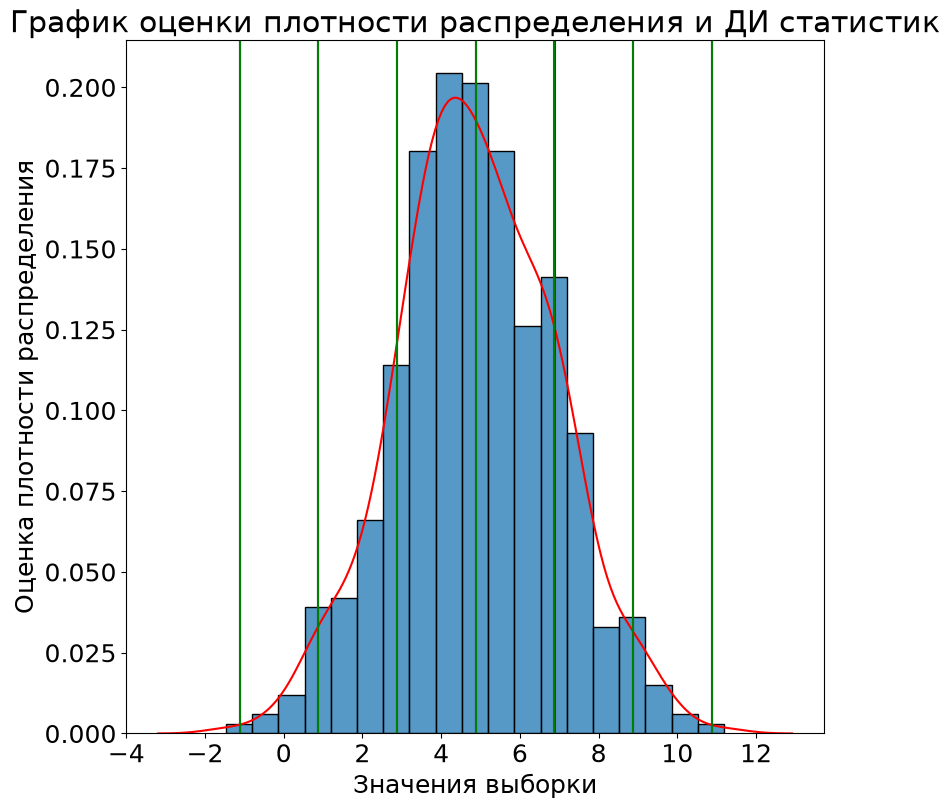

In [68]:
# допустим, x - это массив ваших данных взятый из нормального распределения
x = np.random.normal(5, 2, size=500)  # для примера

# Расчет среднего и СКО на данных
mean_x = np.mean(x)
sse_x = np.std(x, ddof=1)

# строим гистограмму с нормировкой в плотность
counts, bin_edges = np.histogram(x, bins=30, density=True)

# находим середины интервалов
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_widths = np.diff(bin_edges)

# аппроксимация мат. ожидания и дисперсии через гистограмму
mu_hist = np.sum(bin_centers * counts * bin_widths)
var_hist = np.sum(((bin_centers - mu_hist) ** 2) * counts * bin_widths)
sigma_hist = np.sqrt(var_hist)

print(f"Оценка мат. ожидания по гистограмме: {mu_hist:.4f}")
print(f"Оценка среднего по данным: {mean_x:.4f}")
print(f"Оценка стандартного отклонения по гистограмме: {sigma_hist:.4f}")
print(f"Оценка СКО по данным: {sse_x:.4f}")

sns.histplot(x, stat='density')
sns.kdeplot(x, color ="red")
plt.xlabel("Значения выборки")
plt.ylabel("Оценка плотности распределения")
plt.title("График оценки плотности распределения и ДИ статистик")
for x in mu_hist + np.arange(-3, 4) * sigma_hist:
    plt.axvline(x, color="purple")
for x in mean_x + np.arange(-3, 4) * sse_x:
    plt.axvline(x, color="green")
plt.show()

In [69]:
# допустим, x - это массив ваших данных
size = 1000
x = np.random.exponential(4, size=size)  # для примера

# Расчет среднего и СКО на данных
mean_x = np.mean(x)
sse_x = np.std(x, ddof=1)

# строим гистограмму с нормировкой в плотность
counts, bin_edges = np.histogram(x, bins=30, density=True)

# находим середины интервалов
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_widths = np.diff(bin_edges)

# аппроксимация мат. ожидания и дисперсии через гистограмму
mu_hist = np.sum(bin_centers * counts * bin_widths)
var_hist = np.sum(((bin_centers - mu_hist) ** 2) * counts * bin_widths)
sigma_hist = np.sqrt(var_hist)

print(f"Оценка мат. ожидания по гистограмме: {mu_hist:.4f}")
print(f"Оценка среднего по данным: {mean_x:.4f}")
print(f"Оценка стандартного отклонения по гистограмме: {sigma_hist:.4f}")
print(f"Оценка СКО по данным: {sse_x:.4f}")

Оценка мат. ожидания по гистограмме: 3.8942
Оценка среднего по данным: 3.8726
Оценка стандартного отклонения по гистограмме: 3.8381
Оценка СКО по данным: 3.8549


# Доверительные интервалы статистик

В математической статистике мы часто хотим не только оценить параметр генеральной совокупности, но и указать диапазон значений, в котором он лежит с заданной вероятностью. Такой диапазон называется доверительным интервалом, а вероятность, с которой параметр попадёт в интервал, называется уровнем доверия (обычно обозначается $1 − 𝛼$, где $𝛼$ — уровень значимости).

Методика построения доверительных интервалов всегда базируется на двух шагах:

1. *сначала определяется статистика, имеющая известное распределение (распределение Стьюдента для среднего и распределение хи-квадрат для дисперсии)*,
2. *затем по критическим значениям этого распределения вычисляются границы интервала.*

Рассмотрим две классические задачи: доверительный интервал для математического ожидания и доверительный интервал для среднеквадратического отклонения.

## Доверительные интервалы для среднего

Пусть $X_1, X_2, \dots, X_n$​ — выборка из нормального распределения $\mathcal{N}(\mu, \sigma^2)$.

Выборочное среднее определяется как

$$\bar{X} = \frac{1}{n}\sum_{i=1}^n$$
Его математическое ожидание равно $\mu$, а дисперсия — $\frac{\sigma^2}{n}$.

Если $\sigma$ известно, то по ЦПТ

$$\frac{\bar{X} - \mu}{\sigma / \sqrt{n}} \sim \mathcal{N}(0,1).$$
Соответственно, доверительный интервал уровня $1-\alpha$ имеет вид

$$\bar{X} \;\pm\; z_{1-\alpha/2} \cdot \frac{\sigma}{\sqrt{n}},$$

где $z_{1-\alpha/2}$​ — квантиль стандартного нормального распределения.

Если $\sigma$ неизвестно, что чаще всего и бывает, то вместо него используется выборочная стандартная ошибка

$$S = \sqrt{\frac{1}{n-1}\sum_{i=1}^n (X_i - \bar{X})^2}.$$

В этом случае

$$T = \frac{\bar{X} - \mu}{S / \sqrt{n}} \sim t_{n-1},$$

где $t_{n-1}$​ — распределение Стьюдента с $n−1$ степенью свободы.  
Отсюда доверительный интервал уровня $1-\alpha$:

$$\bar{X} \;\pm\; t_{1-\alpha/2, \; n-1} \cdot \frac{S}{\sqrt{n}}.$$

## Рассчет доверительных интервалов для числовых столбцов выборки данных

Расчитаем доверительный интервал статистики среднего для фактора TotalSleepTime

In [70]:
# Для квантилей t - распределения
from scipy.stats import t

# выбираем столбец по которому будем строить доверительный интервал
x = df_sleep['TotalSleepTime']
n = x.size

# Доверительный интервал для среднего (t-интервал)
alpha = 0.05   # Вероятность ошибки доверительного интервала
xbar = float(np.mean(x))     # расчитаем среднее значение
s = float(np.std(x, ddof=1))  # Расчитаем выборочное СКО по данным

se = s / np.sqrt(n)   # Оценка стандартного отклонения среднего

# Расчет критического значения статистики для t-распределения Стьюдента
t_crit = t.ppf(1 - alpha/2, df=n-1)
ci_mean = (xbar - t_crit*se, xbar + t_crit*se)  # расчет ДИ среднего

print(f"Выборочное среднее: {xbar:.6g}")
print(f"Выборочное стандартное отклонение (несмещённое): {s:.6g}")
print(f"t-квантиль: t_(1-alpha/2; {n-1}) = {t_crit:.6g}")
print(f"{int((1-alpha)*100)}-процентный интервал для среднего: [{ci_mean[0]:.6g}, {ci_mean[1]:.6g}]")

Выборочное среднее: 397.324
Выборочное стандартное отклонение (несмещённое): 50.8567
t-квантиль: t_(1-alpha/2; 633) = 1.96372
95-процентный интервал для среднего: [393.358, 401.29]


In [71]:
# Доверительный интервал для среднего (t-интервал)
alpha = 0.01   # Вероятность ошибки доверительного интервала
xbar = float(np.mean(x))
s = float(np.std(x, ddof=1))

se = s / np.sqrt(n)
t_crit = t.ppf(1 - alpha/2, df=n-1)
ci_mean = (xbar - t_crit*se, xbar + t_crit*se)

print(f"Выборочное среднее: {xbar:.6g}")
print(f"Выборочное стандартное отклонение среднего (несмещённое): {s:.6g}")
print(f"{int((1-alpha)*100)}-процентный интервал для среднего: [{ci_mean[0]:.6g}, {ci_mean[1]:.6g}]")

Выборочное среднее: 397.324
Выборочное стандартное отклонение среднего (несмещённое): 50.8567
99-процентный интервал для среднего: [392.106, 402.542]


In [72]:
# Способ построения доверительных интервалов на основе повторных выборок квантилей
x = df_sleep['TotalSleepTime']
# Количество выборок на которых будем оценивать среднее
n = x.size

alpha=0.05
xbar = float(np.mean(x))
# Выбираем записи по n и считаем средние значения
x_mean_array = np.array([np.mean(np.random.choice(x, n, replace=True)) for i in range(n)])
# Ищем квантили в точках alpha/2, 1-alpha/2
quantiles = np.quantile(x_mean_array, [alpha/2, 1-alpha/2])

print(f"Выборочное среднее: {xbar:.6g}")
print(f"{int((1-alpha)*100)}-процентный интервал для среднего: [{quantiles[0]:.6g}, {quantiles[1]:.6g}]")

Выборочное среднее: 397.324
95-процентный интервал для среднего: [393.302, 400.969]


Расчитаем доверительный интервал статистики среднего для всех числовых факторов

### Доверительные интервалы средних для всех данных

In [73]:
from statsmodels.stats.descriptivestats import describe

describe(data=df_sleep,
         stats=["nobs", "mean", "ci"],
         numeric=True, alpha=0.05)

,study,bedtime_mssd,TotalSleepTime,midpoint_sleep,frac_nights_with_data,daytime_sleep,cum_gpa,term_gpa
nobs,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000
mean,3.181388,0.451688,397.323874,398.679186,0.867439,41.164241,3.465596,3.449598
upper_ci,3.283913,0.560168,401.282567,404.339014,0.881369,43.296237,3.499657,3.488555
lower_ci,3.078863,0.343207,393.365181,393.019358,0.853509,39.032246,3.431535,3.410642


In [74]:
describe(data=df_sleep,
         stats=["nobs", "mean", "ci"],
         numeric=True, alpha=0.01)

,study,bedtime_mssd,TotalSleepTime,midpoint_sleep,frac_nights_with_data,daytime_sleep,cum_gpa,term_gpa
nobs,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000,634.000000
mean,3.181388,0.451688,397.323874,398.679186,0.867439,41.164241,3.465596,3.449598
upper_ci,3.316129,0.594255,402.526479,406.117461,0.885746,43.966158,3.510360,3.500796
lower_ci,3.046647,0.309120,392.121269,391.240911,0.849131,38.362324,3.420832,3.398401


Доверительные интервалы для средних строятся абсолютно таким же образом

## Доверительный интервал для среднеквадратического отклонения

Для выборочного среднеквадратического отклонения

$$S=\frac{1}{n-1}\sum_{i=1}^n (X_i - \bar{X})^2$$
справедливо точное соотношение

$$\frac{(n-1)S^2}{\sigma^2} \sim \chi^2_{n-1},$$

где $\chi^2_{n-1}$​ — распределение хи-квадрат с $n-1$ степенью свободы.

Из этого факта получаем доверительный интервал уровня $1-\alpha$ для выборочной дисперсии:

$$\frac{(n-1)S^2}{\chi^2_{1-\alpha/2, \; n-1}} \;\leq\; \sigma^2 \;\leq\; \frac{(n-1)S^2}{\chi^2_{\alpha/2, \; n-1}},$$

где $\chi^2_{\gamma, \; n-1}$​ обозначает квантиль распределения хи-квадрат.

Поскольку выборочноге среднеквадратическое отклонение $\sigma = \sqrt{\sigma^2}$​, доверительный интервал для него имеет вид:

$$\sqrt{\frac{(n-1)S^2}{\chi^2_{1-\alpha/2, \; n-1}}} \;\leq\; \sigma \;\leq\; \sqrt{\frac{(n-1)S^2}{\chi^2_{\alpha/2, \; n-1}}}$$.



In [75]:
# Для квантилей t - распределения
from scipy.stats import chi2

# выбираем столбец по которому будем строить доверительный интервал
x = df_sleep['TotalSleepTime']
n = x.size

# Доверительный интервал для среднего (t-интервал)
alpha = 0.05   # Вероятность ошибки доверительного интервала
xbar = float(np.mean(x))     # расчитаем среднее значение
s = float(np.std(x, ddof=1))  # Расчитаем выборочное СКО по данным

se = s / np.sqrt(n)   # Оценка стандартного отклонения среднего
# Доверительный интервал для стандартного отклонения на основе хи-квадрат
chi2_low = chi2.ppf(1 - alpha/2, df=n-1)
chi2_high = chi2.ppf(alpha/2, df=n-1)

# Интервал для дисперсии
var_low = (n-1) * (s**2) / chi2_low
var_high = (n-1) * (s**2) / chi2_high

# Интервал для стандартного отклонения
sigma_ci = (np.sqrt(var_low), np.sqrt(var_high))

print(f"Квантили хи-квадрат: chi2_(1-alpha/2; {n-1}) = {chi2_low:.6g}, chi2_(alpha/2; {n-1}) = {chi2_high:.6g}")
print(f"{int((1-alpha)*100)}%-й доверительный интервал для σ: [{sigma_ci[0]:.6g}, {sigma_ci[1]:.6g}]")

Квантили хи-квадрат: chi2_(1-alpha/2; 633) = 704.612, chi2_(alpha/2; 633) = 565.176
95%-й доверительный интервал для σ: [48.2031, 53.8218]


In [76]:
# Способ построения доверительных интервалов на основе повторных выборок квантилей
x = df_sleep['TotalSleepTime']
# Количество выборок на которых будем оценивать среднее
n = x.size

alpha=0.05
s = float(np.std(x))
# Выбираем записи по n и считаем средние значения
x_std_array = np.array([np.std(np.random.choice(x, n, replace=True)) for i in range(n)])
# Ищем квантили в точках alpha/2, 1-alpha/2
quantiles = np.quantile(x_std_array, [alpha/2, 1-alpha/2])

print(f"Выборочное СКО: {s:.6g}")
print(f"{int((1-alpha)*100)}-процентный интервал для СКО: [{quantiles[0]:.6g}, {quantiles[1]:.6g}]")

Выборочное СКО: 50.8166
95-процентный интервал для СКО: [47.5938, 53.8775]


## Оценка ДИ на основе повторных подвыборок

В классической математической статистике доверительный интервал (ДИ) для параметра генеральной совокупности (например, математического ожидания $\mu$ или дисперсии $\sigma^2$) строится на основе известных распределений статистик. Например, при нормальном распределении данных и известной дисперсии можно использовать стандартное нормальное распределение, а при неизвестной дисперсии – распределение Стьюдента. Однако на практике распределение генеральной совокупности часто неизвестно или не удовлетворяет строгим предпосылкам.

В этом случае применяются **методы повторных подвыборок** – прежде всего **бутстреп** (bootstrap) и **перестановочные методы** (permutation methods). Эти методы позволяют оценивать вариативность статистик напрямую на основе выборки, без обращения к асимптотическим формулам.

### Основная идея бутстрэпа

Пусть у нас есть выборка

$$X = \{x_1, x_2, \ldots, x_n\}, \quad x_i \sim F,$$

где $F$ – неизвестное распределение. Мы хотим построить доверительный интервал для параметра $\theta = T(F)$ (например, математическое ожидание). На практике мы используем оценку

$$\hat{\theta} = T(\hat{F}_n),$$

где $\hat{F}_n$​ – эмпирическое распределение выборки (доля масс сосредоточена в точках наблюдений).

Так как распределение $\hat{\theta}$ неизвестно, мы **имитируем** его: многократно извлекаем _бутстреп-подвыборки_ из $\hat{F}_n$​. Это эквивалентно повторной выборке из исходных данных с возвращением.

Для каждой бутстреп-подвыборки $X^*_b = \{x_1^*, \ldots, x_n^*\}$} вычисляется статистика:

$$\hat{\theta}^*_b = T(X^*_b), \quad b = 1, \ldots, B.$$

Таким образом мы получаем эмпирическое распределение $\hat{\theta}^*_1, \ldots, \hat{\theta}^*_B$​, которое служит приближением к истинному распределению $\hat{\theta}$.

### Методы построения доверительных интервалов

Существует несколько способов построить доверительные интервалы на основе бутстрэпа.

#### (a) Квантильный интервал (Percentile interval)

Берём эмпирическое распределение $\hat{\theta}^*$ и строим $(1-\alpha)$-интервал как:

$$\big[ \hat{\theta}^*_{\alpha/2}, \; \hat{\theta}^*_{1-\alpha/2} \big],$$

где $\hat{\theta}^*_{p}$ – $p$-квантиль распределения бутстреп-оценок.

Это наиболее простой и наглядный метод.

#### (b) Интервал по стандартной ошибке

Мы оцениваем стандартную ошибку (Standard Error, SE) как:

$$\widehat{\text{SE}} = \sqrt{\frac{1}{B-1} \sum_{b=1}^B \left(\hat{\theta}^*_b - \bar{\theta}^* \right)^2},$$

где

$$\bar{\theta}^* = \frac{1}{B} \sum_{b=1}^B \hat{\theta}^*_b.$$

Тогда доверительный интервал строится по аналогии с классическими методами:

$$\big[ \hat{\theta} \;-\; z_{1-\alpha/2} \cdot \widehat{\text{SE}}, \quad \hat{\theta} \;+\; z_{1-\alpha/2} \cdot \widehat{\text{SE}} \big],$$

где $z_{1-\alpha/2}$​ – квантиль стандартного нормального распределения.

### 3. Перестановочные методы

Если мы хотим проверить гипотезу или построить доверительный интервал при фиксированной нулевой гипотезе, можно использовать перестановки. Например, в задачах сравнения средних перестановочный тест строится на случайных переименовках меток классов. ДИ в этом случае формируется аналогично – на основе распределения статистики при перестановках.

### 4. Интерпретация доверительного интервала при бутстрепе

Важно понимать, что бутстреповский ДИ – это не утверждение о том, что параметр _обязательно_ находится внутри интервала. Правильная интерпретация: если бы мы многократно повторяли процесс бутстрэпа и строили интервалы, то доля интервалов, содержащих истинный параметр, стремилась бы к $(1-\alpha)$.

### 5. Практические шаги

1. Задаём число повторов $B$ (обычно от 1000 до 10000).
2. Генерируем бутстреп-подвыборки того же размера $n$.
3. Вычисляем статистику на каждой подвыборке.
4. Строим распределение бутстреп-оценок.
5. Из этого распределения строим доверительный интервал одним из описанных способов.

Таким образом, методы повторных подвыборок позволяют отказаться от строгих предположений о распределении данных и использовать только эмпирическую информацию. Это особенно важно для реальных данных, где нормальность и другие классические предпосылки часто не выполняются.

In [77]:
x = df_sleep['TotalSleepTime']
n = x.size


def bootstrap_interval(x, stat=None, b=None, alpha=None, seed=None):
    # Зададим начальные значения
    stat = np.mean if stat is None else stat
    b = x.size if b is None else b
    alpha = 0.05 if alpha is None else alpha

    np.random.seed(seed)

    stat_x = stat(x)
    # Сделаем выборку оценок статистик на подвыборках
    x_bootstrap = [stat(np.random.choice(x, n, replace=True)) for i in range(b)]

    stat_interval = np.quantile(x_bootstrap, (alpha/2, 1-alpha/2))
    return stat_x, stat_interval[0], stat_interval[1]


quantile_33 = bootstrap_interval(x, np.std)
quantile_33

(np.float64(50.816601547954704),
 np.float64(47.55534956615651),
 np.float64(54.18345631330648))

## Интерпретация

Важно подчеркнуть, что доверительный интервал не гарантирует, что параметр "обязательно" находится в этих границах. Верная интерпретация звучит так: если бы мы многократно повторяли эксперимент, каждый раз строили доверительный интервал, то доля интервалов, содержащих истинное значение параметра, в среднем составила бы $1-\alpha$


# Задания. Статистический анализ факторов и доверительные интервалы статистик

In [78]:
import numpy as np
import pandas as pd
import statsmodels as sm
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import scipy.stats as stats
from statsmodels.graphics.gofplots import qqplot
# Для квантилей t - распределения
from scipy.stats import t, chi2

# Игнорирование предупреждений связанных с версиями
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Задание №1. Загрузка данных и предпросмотр

- 1.1. Импортировать данные `HepatitisCdata.csv`
- 1.2. Оценить наличие пропусков в данных с помощью `.info` (очистить пропуски и нетипичные значения в данных если есть)
- 1.3. Оценить описательные статистики по набору данных и сделать предварительные выводы

In [79]:
#------------------ 1.1 -----------------
df = pd.read_csv('./HepatitisCdata.csv', sep=',')
#------------------ 1.2 -----------------
df.info()
df = df.drop('Unnamed: 0', axis=1)
cols = list(df.columns)
null_markers = ['null', 'NA', 'N/A', '', ' ', 'unknown', 'Unknown']
for col in cols:
    if df[col].dtype == 'object':
            df[col] = df[col].replace(null_markers, np.nan)
    if df[col].isna().sum() != 0:
        print(f"Column {col} have null values ({df[col].isna().sum()})")
df = df.dropna()
print("-----------All columns is cleared------------")
(print(df.isnull().sum()))
#------------------ 1.3 -----------------
print("=== Числовые столбцы ===")
print(df.describe(include=[np.number]))

print("\n=== Категориальные столбцы ===")
print(df.describe(include=['str']))

<class 'pandas.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  615 non-null    int64  
 1   Category    615 non-null    str    
 2   Age         615 non-null    int64  
 3   Sex         614 non-null    str    
 4   ALB         614 non-null    float64
 5   ALP         597 non-null    float64
 6   ALT         614 non-null    float64
 7   AST         615 non-null    float64
 8   BIL         615 non-null    float64
 9   CHE         615 non-null    float64
 10  CHOL        605 non-null    float64
 11  CREA        615 non-null    float64
 12  GGT         615 non-null    float64
 13  PROT        614 non-null    float64
dtypes: float64(10), int64(2), str(2)
memory usage: 67.4 KB
Column Sex have null values (1)
Column ALB have null values (1)
Column ALP have null values (18)
Column ALT have null values (1)
Column CHOL have null values (10)
Column PROT have null value

# Задание №2. Визуальный анализ показателей
- 2.1. Построить визуализацию числовых показателей
- 2.2. Визуально оценить форму распределения, типичные значения, выбросы по ящику с усами
- 2.3. Сделать предварительные выводы о распределениях данных


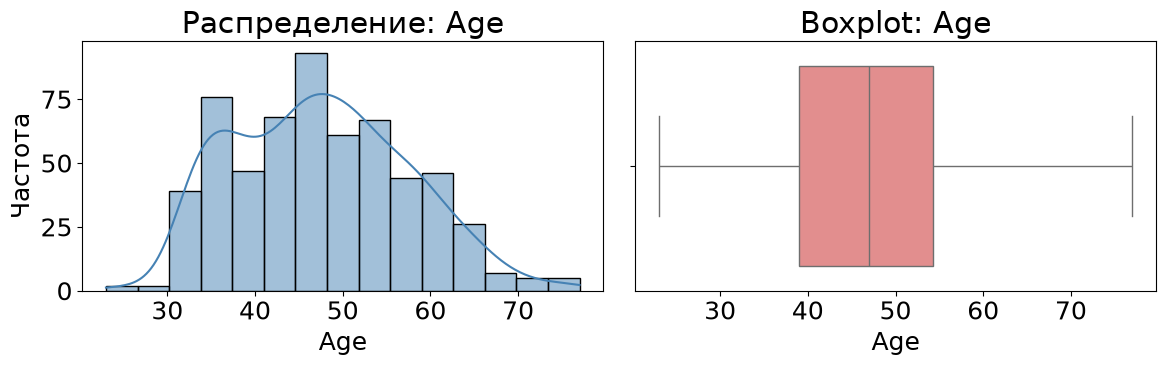

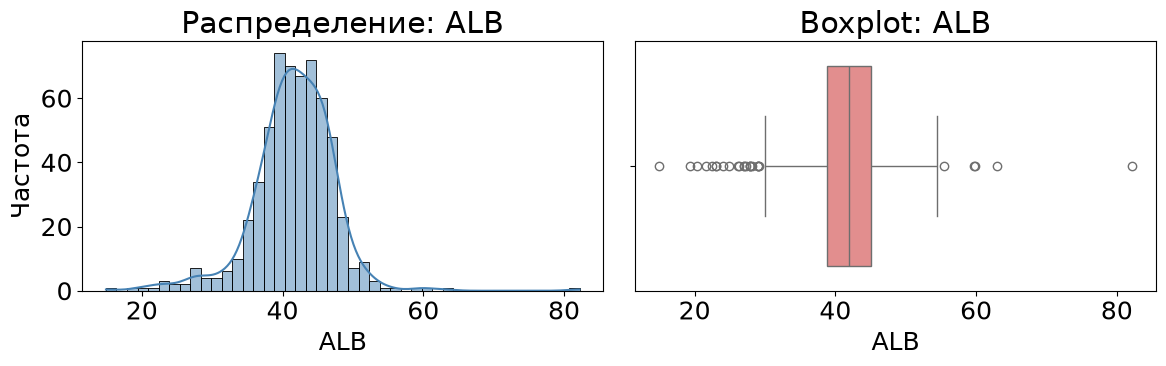

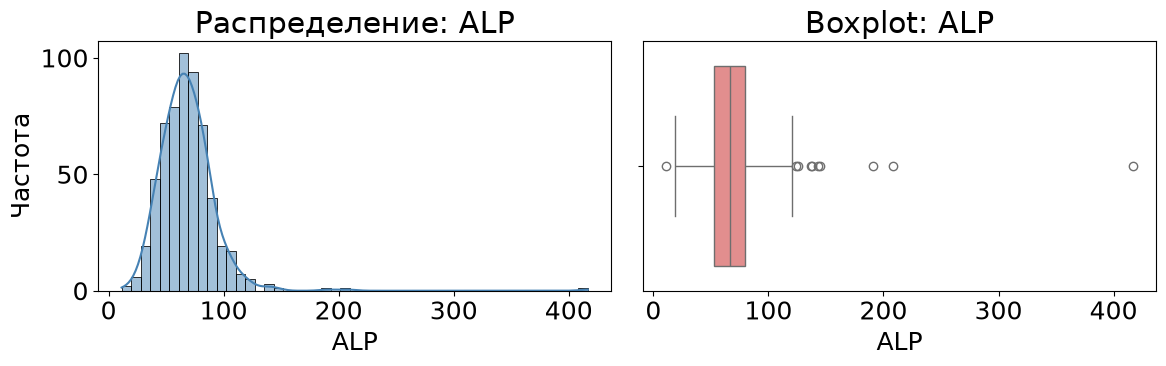

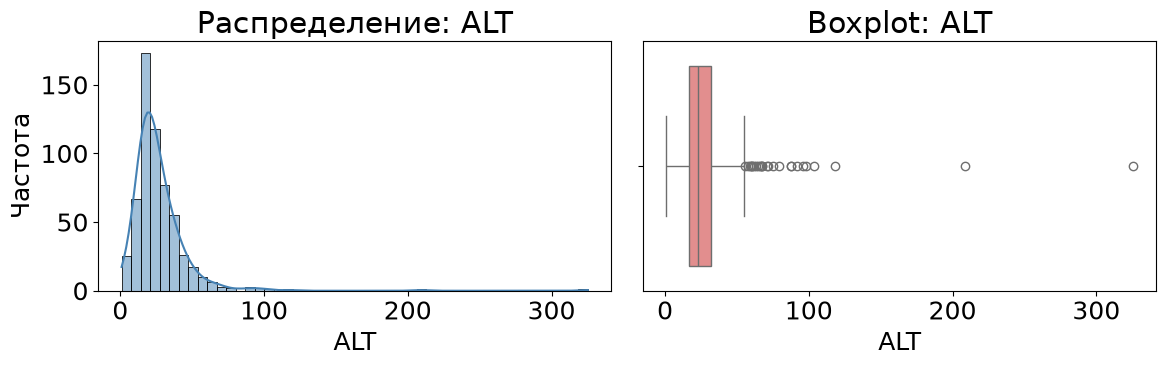

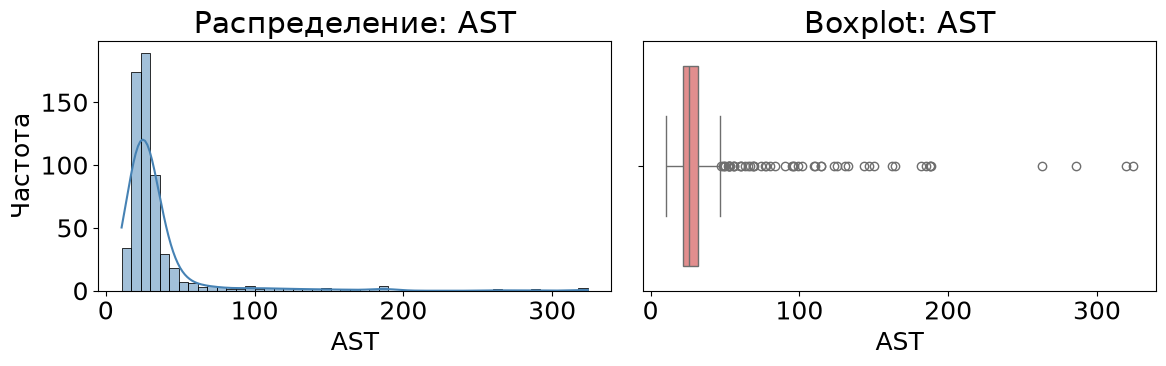

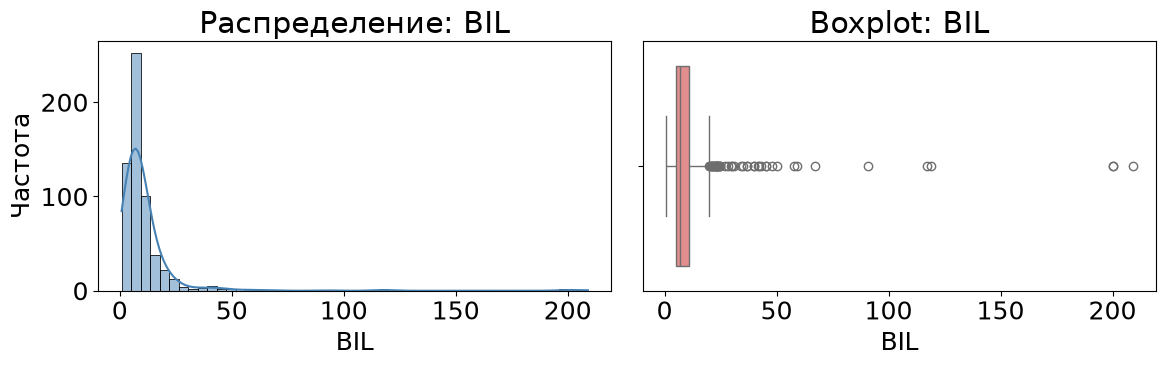

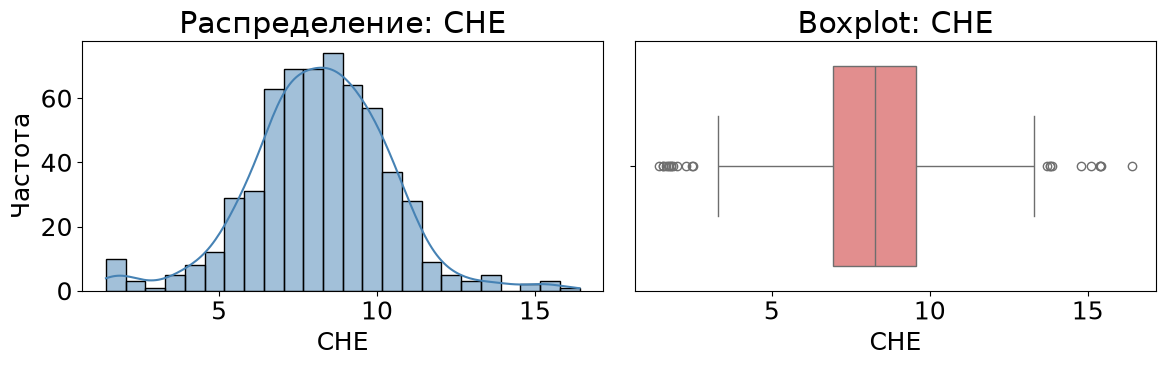

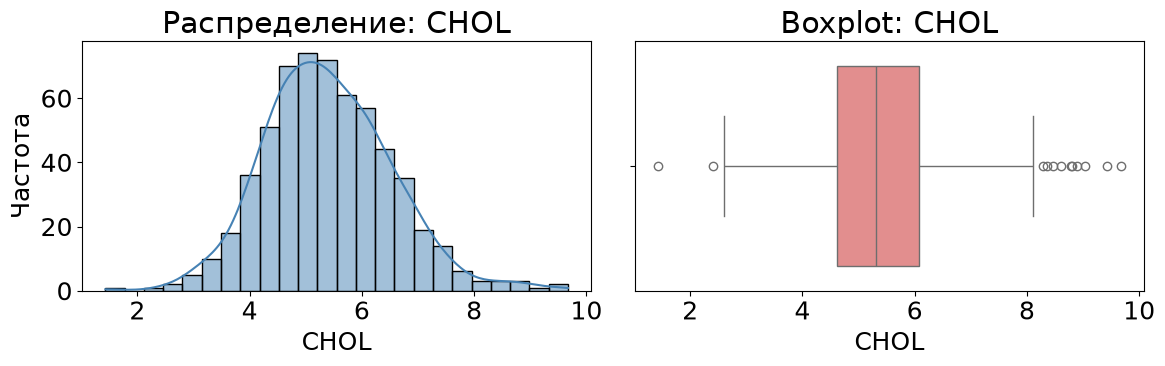

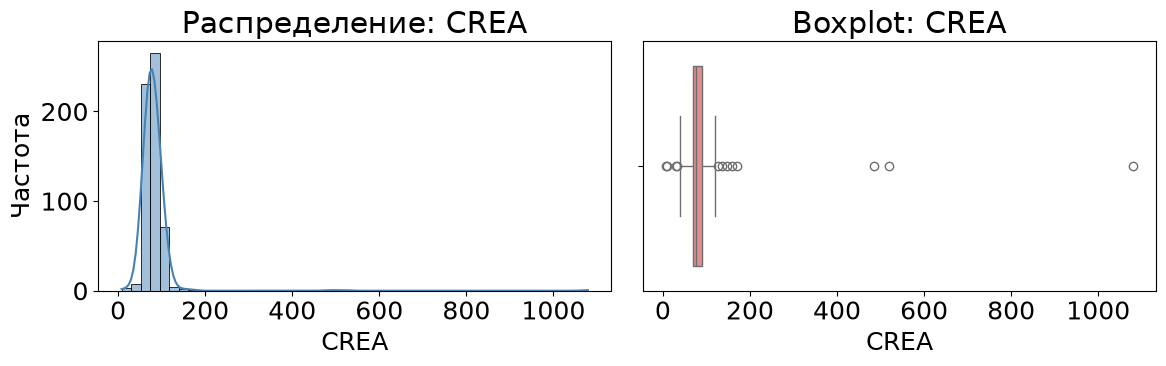

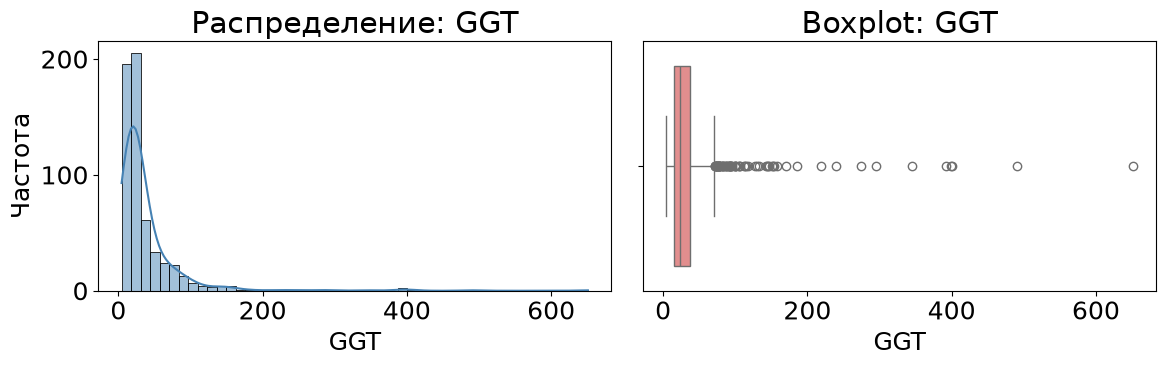

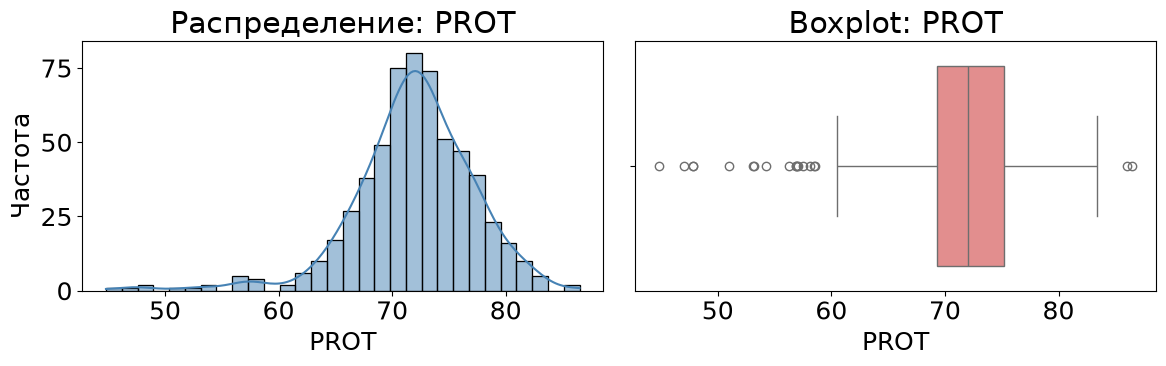

In [80]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Гистограмма + KDE
    sns.histplot(df[col].dropna(), kde=True, ax=axes[0], color='steelblue')
    axes[0].set_title(f'Распределение: {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Частота')

    # Ящик с усами
    sns.boxplot(x=df[col].dropna(), ax=axes[1], color='lightcoral')
    axes[1].set_title(f'Boxplot: {col}')
    axes[1].set_xlabel(col)

    plt.tight_layout()
    plt.show()

### Предварительный вывод
# 1. Неоднородность распределений
Выборка содержит показатели с кардинально разными типами распределений, что не позволяет применять единый подход ко всем признакам:
- Симметричные / близкие к нормальному: PROT, CHOL, ALB, CHE. Распределения этих признаков имеют колоколообразную форму без ярко выраженной асимметрии. Для них в дальнейшем допустимо применение классических параметрических методов (например, t-теста или ANOVA) при условии проверки гомоскедастичности.

- Асимметричные с тяжелым правым хвостом: ALP, ALT, AST, BIL, CREA, GGT. Это классическая картина для клинических биохимических анализов, где большинство значений сосредоточено в области нормы, но у части пациентов показатели резко возрастают из-за патологий (заболевания печени, почек и т.д.).

- Многомодальное распределение: Age (наблюдаются два отчетливых пика). Это может указывать на неоднородность выборки (например, смесь двух возрастных групп пациентов) и требует дополнительного изучения.

# 2. Проблема выбросов
Для целого ряда биохимических маркеров (ALP, ALT, AST, BIL, CREA, GGT) характерно огромное количество выбросов в правой части распределения.
Важно понимать, что в контексте медицинских данных это, как правило, не ошибки ввода, а биологическая реальность (пациенты с острыми состояниями). Однако для статистических моделей, предполагающих нормальность, такие данные необходимо либо трансформировать (например, с помощью преобразования Бокса-Кокса или логарифмирования), либо использовать робастные (непараметрические) методы, чтобы экстремальные значения не искажали результаты.
# 3. Медиана как надежная мера центра

Поскольку для большинства медицинских показателей распределения сильно скошены вправо, среднее арифметическое будет завышенным из-за влияния правых выбросов. В качестве «типичного значения» для таких показателей (ALP, CREA, GGT и др.) следует опираться на медиану и межквартильный размах (IQR), которые устойчивы к аномалиям.

# Задание №3. Оценка доверительных интервалов статистик
- 3.1. Оценить статистику и доверительные интервалы средних значений для $\alpha=(0.05, 0.01, 0.001)$.
- 3.2. Сравнить и сделать выводы о значениях ДИ среднего при уменьшении уровня доверия $\alpha$
- 3.3. Оценить статистику и доверительные интервалы СКО для $\alpha=(0.05, 0.01, 0.001)$.
- 3.4. Сравнить и сделать выводы о значения ДИ СКО при уменьшении уровня доверия $\alpha$ (к чему в пределе стремится левая граница, как растет значение правой границы)
- 3.5. С помощью Бутстрепа оценить доверительные интервалы для статистик (медиана, 25 процентиль, 75 процентиль) для показателя ALP . Сделайте гистограммы бутстреп-подвыборок, на графиках отобразите ДИ статистик при $\alpha$=0,05 и $\alpha$=0,001


--------------------------- 3.1 -----------------------


=== Age ===  n=588, mean=47.4439, s=9.91936
  alpha=0.05: t_crit=1.96401, 95.0%-ДИ среднего = [46.6405, 48.2473]
  alpha=0.01: t_crit=2.58423, 99.0%-ДИ среднего = [46.3868, 48.501]
  alpha=0.001: t_crit=3.30718, 99.9%-ДИ среднего = [46.091, 48.7967]

=== ALB ===  n=588, mean=41.6216, s=5.76633
  alpha=0.05: t_crit=1.96401, 95.0%-ДИ среднего = [41.1546, 42.0886]
  alpha=0.01: t_crit=2.58423, 99.0%-ДИ среднего = [41.0071, 42.2361]
  alpha=0.001: t_crit=3.30718, 99.9%-ДИ среднего = [40.8352, 42.408]

=== ALP ===  n=588, mean=68.1505, s=25.9346
  alpha=0.05: t_crit=1.96401, 95.0%-ДИ среднего = [66.0499, 70.2511]
  alpha=0.01: t_crit=2.58423, 99.0%-ДИ среднего = [65.3866, 70.9144]
  alpha=0.001: t_crit=3.30718, 99.9%-ДИ среднего = [64.6134, 71.6876]

=== ALT ===  n=588, mean=26.5685, s=20.8802
  alpha=0.05: t_crit=1.96401, 95.0%-ДИ среднего = [24.8774, 28.2597]
  alpha=0.01: t_crit=2.58423, 99.0%-ДИ среднего = [24.3433, 28.7938]
  a

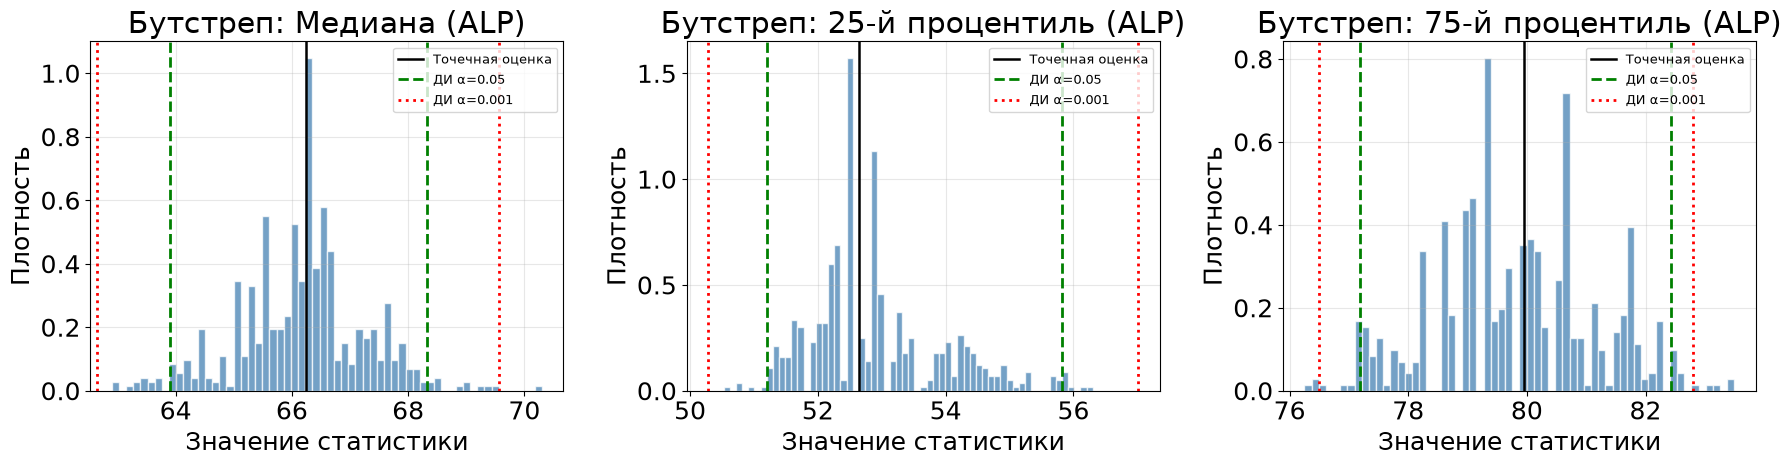

In [81]:
#------------------ 3.1 -----------------
print("\n--------------------------- 3.1 -----------------------\n")
from scipy.stats import t, chi2
import numpy as np
import matplotlib.pyplot as plt

alphas = (0.05, 0.01, 0.001)
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    x = df[col]
    n = x.size
    xbar = float(np.mean(x))
    s = float(np.std(x, ddof=1))
    se = s / np.sqrt(n)

    print(f"\n=== {col} ===  n={n}, mean={xbar:.6g}, s={s:.6g}")
    for alpha in alphas:
        t_crit = t.ppf(1 - alpha/2, df=n-1)
        ci_mean = (xbar - t_crit*se, xbar + t_crit*se)
        print(f"  alpha={alpha}: t_crit={t_crit:.6g}, "f"{int((1-alpha)*1000)/10}%-ДИ среднего = "f"[{ci_mean[0]:.6g}, {ci_mean[1]:.6g}]")

#------------------ 3.3 -----------------
print("\n--------------------------- 3.3 -----------------------\n")
for col in numeric_cols:
    x = df[col]
    n = x.size
    s = float(np.std(x, ddof=1))

    print(f"\n=== {col} ===  n={n}, s={s:.6g}")
    for alpha in alphas:
        chi2_low  = chi2.ppf(1 - alpha/2, df=n-1)
        chi2_high = chi2.ppf(alpha/2,     df=n-1)

        var_low  = (n-1) * (s**2) / chi2_low
        var_high = (n-1) * (s**2) / chi2_high

        sigma_ci = (np.sqrt(var_low), np.sqrt(var_high))
        print(f"  alpha={alpha}: chi2_low={chi2_low:.6g}, chi2_high={chi2_high:.6g}, "f"{int((1-alpha)*1000)/10}%-ДИ σ = "f"[{sigma_ci[0]:.6g}, {sigma_ci[1]:.6g}]")

#------------------ 3.5 -----------------
print("\n--------------------------- 3.5 -----------------------\n")
x = df['ALP']
n = x.size
b = n

# готовые функции из файла
median_x, med_lo05, med_hi05     = bootstrap_interval(x, np.median, alpha=0.05,  seed=42)
median_x, med_lo001, med_hi001   = bootstrap_interval(x, np.median, alpha=0.001, seed=42)

q25_x, q25_lo05, q25_hi05        = bootstrap_interval(x, lambda v: np.quantile(v, 0.25), alpha=0.05,  seed=42)
q25_x, q25_lo001, q25_hi001      = bootstrap_interval(x, lambda v: np.quantile(v, 0.25), alpha=0.001, seed=42)

q75_x, q75_lo05, q75_hi05        = bootstrap_interval(x, lambda v: np.quantile(v, 0.75), alpha=0.05,  seed=42)
q75_x, q75_lo001, q75_hi001      = bootstrap_interval(x, lambda v: np.quantile(v, 0.75), alpha=0.001, seed=42)

print(f"Медиана:            point={median_x:.3f}  " f"α=0.05: [{med_lo05:.3f}; {med_hi05:.3f}]  " f"α=0.001: [{med_lo001:.3f}; {med_hi001:.3f}]")
print(f"25-й процентиль:    point={q25_x:.3f}  " f"α=0.05: [{q25_lo05:.3f}; {q25_hi05:.3f}]  " f"α=0.001: [{q25_lo001:.3f}; {q25_hi001:.3f}]")
print(f"75-й процентиль:    point={q75_x:.3f}  " f"α=0.05: [{q75_lo05:.3f}; {q75_hi05:.3f}]  " f"α=0.001: [{q75_lo001:.3f}; {q75_hi001:.3f}]")

# массивы бутстреп-оценок
x_boot_median = np.array([np.median(np.random.choice(x, n, replace=True)) for _ in range(b)])
x_boot_q25    = np.array([np.quantile(np.random.choice(x, n, replace=True), 0.25) for _ in range(b)])
x_boot_q75    = np.array([np.quantile(np.random.choice(x, n, replace=True), 0.75) for _ in range(b)])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

panels = [('Медиана',         x_boot_median, median_x, med_lo05,  med_hi05,  med_lo001,  med_hi001),('25-й процентиль', x_boot_q25,    q25_x,    q25_lo05,  q25_hi05,  q25_lo001,  q25_hi001),('75-й процентиль', x_boot_q75,    q75_x,    q75_lo05,  q75_hi05,  q75_lo001,  q75_hi001),]

for ax, (title, arr, point, lo05, hi05, lo001, hi001) in zip(axes, panels):
    ax.hist(arr, bins=60, color='steelblue', alpha=0.75,
            edgecolor='white', density=True)
    ax.axvline(point, color='black', lw=1.8, label='Точечная оценка')
    ax.axvline(lo05,  color='green', ls='--', lw=2, label='ДИ α=0.05')
    ax.axvline(hi05,  color='green', ls='--', lw=2)
    ax.axvline(lo001, color='red',   ls=':',  lw=2, label='ДИ α=0.001')
    ax.axvline(hi001, color='red',   ls=':',  lw=2)
    ax.set_title(f'Бутстреп: {title} (ALP)')
    ax.set_xlabel('Значение статистики')
    ax.set_ylabel('Плотность')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

#### Пример вычисления 25 процентиля

In [82]:
import numpy as np

data_sample = [29, 29, 28, 13, 23, 9, 11, 23, 25, 12, 13, 14]

def stat_25q(x):
    return np.quantile(x, 0.25)

stat_25q(data_sample)

np.float64(12.75)